# What genetic architecture does the fitted landscape reproduce?

**Agreement is conditional on the observation model, and on how variation is weighted.**
Shared-stop observations give a local interaction-order spectrum and sign-epistasis
frequency close to measured TrpB when each cube has equal weight. They put too much
of the pooled fitness variance into interactions. The intrinsic sigmoid landscapes
have much less local high-order signal and sign epistasis than measured TrpB.

This notebook reconstructs deterministic descriptors from completed RUN-186. It
fits no coefficients and draws no new landscape or measurement realization. WHT
spectra and sign epistasis were **not** targets of this run's rolled-back fitting
objective. The empirical panel has already been inspected in earlier analyses;
this is diagnostic evidence, not new independent biological validation.

In [1]:
from pathlib import Path
import os
import sys
os.environ.setdefault('MPLBACKEND', 'Agg')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/ana072-architecture-mpl')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AIM.md').exists())
ANA = ROOT / 'analyses/2026-11-25_ANA-072_run-186-trpb-landscape-behaviour-architecture-and-difficulty-proxies'
sys.path.insert(0, str(ANA / 'notebooks'))
import architecture_tools as architecture
import pandas as pd
from IPython.display import Image, display
frame, validation = architecture.build(ROOT)
print(f"Authenticated {len(validation['source_files'])} frozen files; independently reproduced all {validation['archived_rows_replayed']} archived architecture rows.")
print('Maximum descriptor replay difference:', max(validation['maximum_absolute_replay_difference'].values()))

Authenticated 53 frozen files; independently reproduced all 363 archived architecture rows.
Maximum descriptor replay difference: 2.220446049250313e-16


## What is measured here

A local cube contains all 16 combinations of two selected amino acids at each of
four sites. The 32 measured confirmation cubes are complete. Each synthetic seed
contributes its eight assigned cubes; the assignment changes across seeds. The
figures show all eight **fresh relative to calibration** seeds. The 16 reused
seeds and all three resolutions remain in the accompanying numerical tables.
Seed ranges combine variation in generator realization and assigned cube geometry;
they are neither biological replicates nor confidence intervals.

For cube values $y(x)$, the orthogonal Walsh coefficient is
$\widehat y(S)=2^{-4}\sum_x y(x)(-1)^{\sum_{i\in S}x_i}$.
Order-$k$ power is $P_k=\sum_{|S|=k}\widehat y(S)^2$, with
$\sum_{k=1}^4P_k=\operatorname{Var}(y)$ (population variance). This notebook
checks that identity independently for every cube.

- **Equal-cube fractions:** average $P_k/\sum_jP_j$ over cubes whose variance
  exceeds the declared resolution floor. A low-variance cube can count as much
  as a high-variance cube.
- **Pooled fractions:** $\sum_cP_{k,c}/\sum_c\sum_jP_{j,c}$. This gives more
  weight to cubes carrying more absolute fitness variation.

These local binary spectra are not the full 20-allele landscape's reference-free
decomposition and do not identify biological interaction coefficients. The
measured values include assay error; no empirical noise deconvolution is performed.

## Figure 3 — Equal-cube agreement does not imply pooled agreement

Markers show seed medians; whiskers show the 10th–90th percentiles across eight
seeds. The black curve is the 32-cube measured value. The three model curves use
their separately fitted settings: no-noise intrinsic fitness, independent-difference
observations, and shared-stop-sensitivity observations. This is not the same fitted
curve subjected to three noise treatments. Pointwise median fractions need not
add to exactly one; every individual seed's available spectrum does.

The historical primary resolution is $\epsilon=0.001$ times the frozen calibration
range, approximately $1.94\times10^{-4}$ in native fitness units. All fresh-seed
intrinsic and observed cubes have resolvable power at this resolution.

Shared-stop observations have median equal-cube epistatic and order-3–4 fractions
**0.651 and 0.274**, versus **0.688 and 0.316** measured. Their pooled fractions
are **0.561 and 0.202**, versus **0.330 and 0.086** measured. This is useful coarse
local resemblance with a substantial variance-weighted mismatch, not recovery
of the complete empirical architecture.

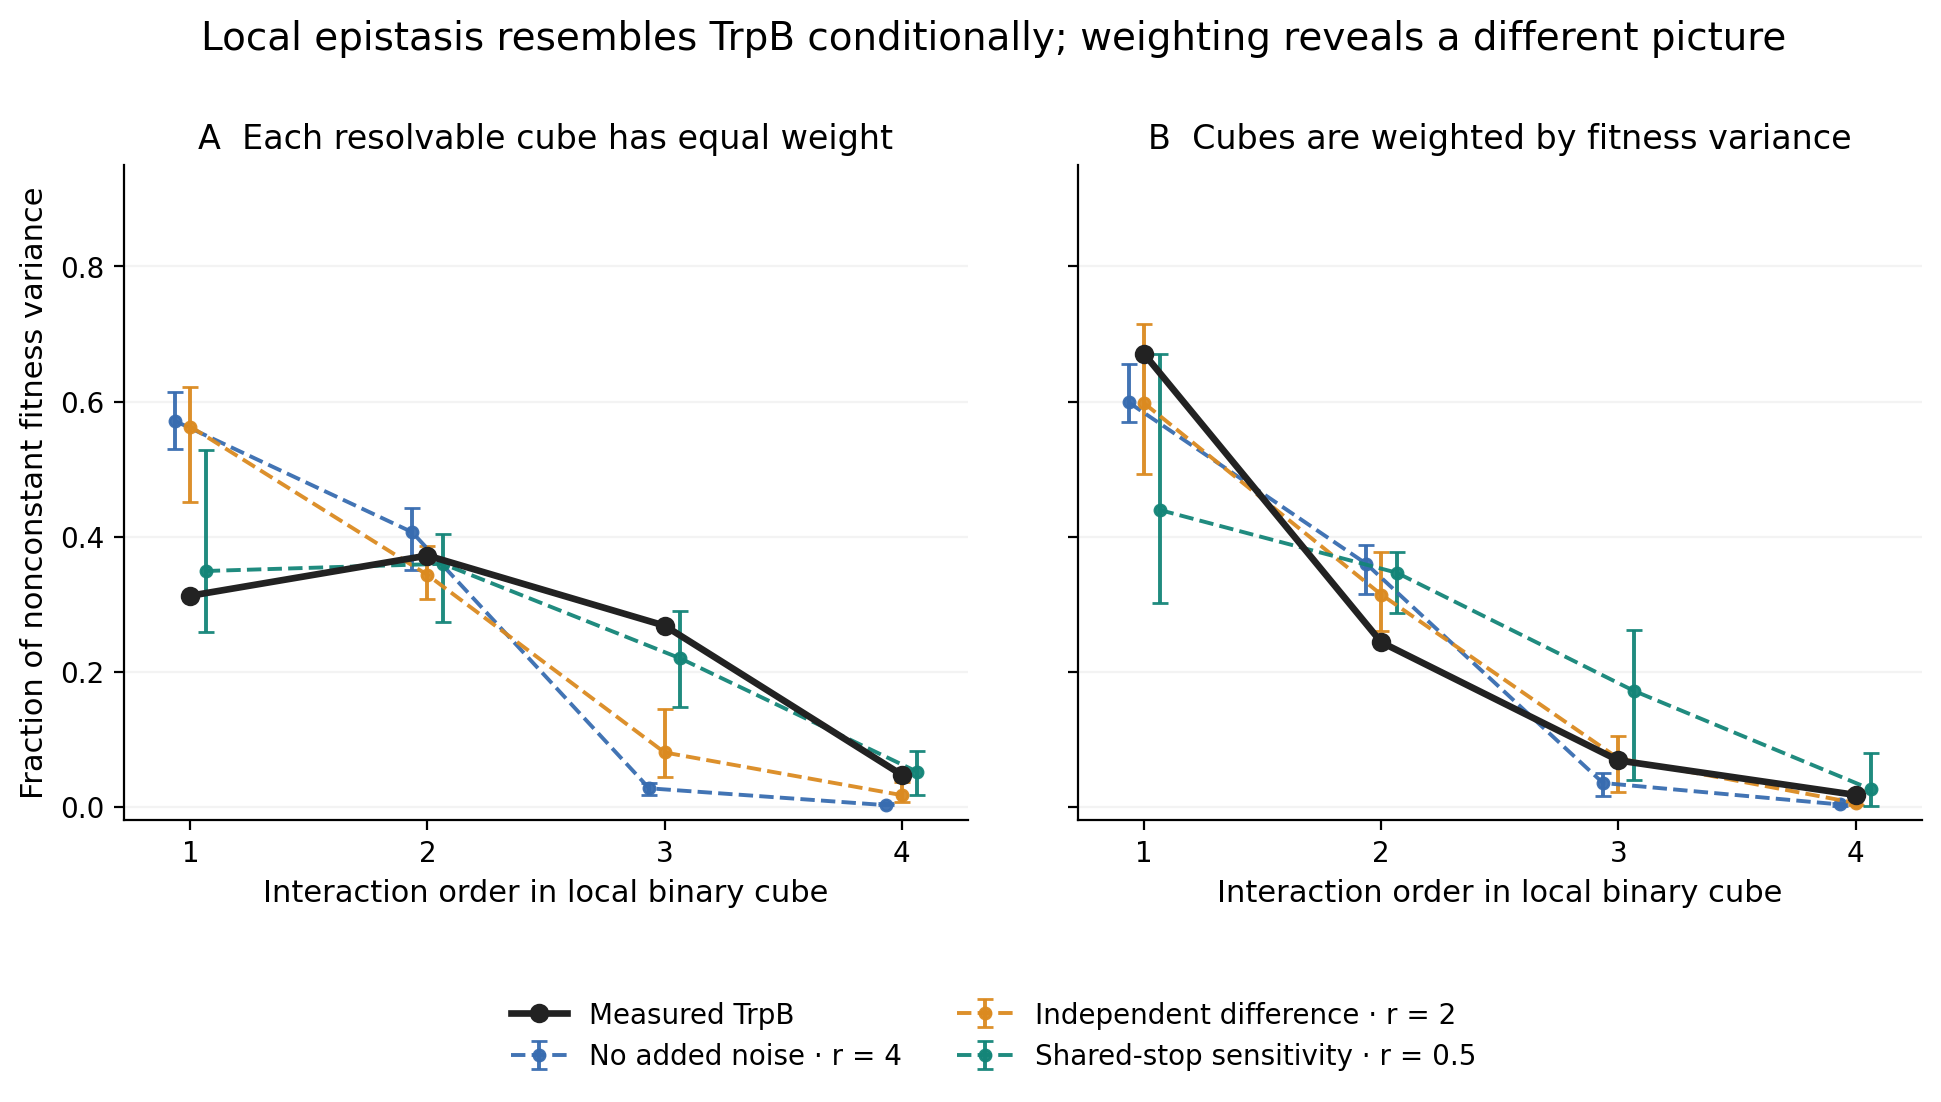

In [2]:
display(Image(filename=str(architecture.spectrum_figure(frame, ANA))))

## Figure 4 — Specific pairwise effects, a nonlinear readout and observations have distinct roles

The generator's latent score is $z(x)=a(x)+r\,g(x)$, where $a$ is the supplied
profile's additive field and $g$ comprises six full centered 20×20 pair tables.
This run keeps Gaussian pair coefficients; Gamma concentration is disabled.
Restricting this score to any binary cube leaves **only orders 0, 1 and 2**.
The largest reconstructed latent order-3–4 fraction is below $4\times10^{-32}$,
consistent with floating-point roundoff. This is a construction check, not a
fitted biological result.

The sigmoid produces nonzero observable order-3–4 power even with a pairwise
latent score. Because it is strictly increasing, it preserves the signs of exact
mutation effects. The recorded latent and intrinsic maps have identical sign and
reciprocal-sign fractions at zero threshold for every seed and setting. Higher
observable interaction order alone therefore does not mean more sign reversals
or additional uphill traps.

The observation layer can change both spectra and mutation signs. At the primary
positive resolution, the shared-stop setting moves median sign epistasis from
**0.099 intrinsic to 0.641 observed**, against **0.651 measured**. Reciprocal sign
epistasis changes **0.010 → 0.315**, against **0.296 measured**. These matches rely
heavily on the observation assumption; shared-stop is a sensitivity model, not an
identified TrpB assay-error mechanism.

**This figure uses zero threshold for sign changes**, so latent scores and fitness
can be compared without imposing a common numerical threshold on different units.
A face has sign epistasis when at least one mutation reverses sign between its two
backgrounds; reciprocal sign epistasis requires both mutations to reverse sign.
It counts 24 faces per cube, retaining every face in the denominator. Faint points
show individual seeds. No added-noise setting has no separate observed layer.

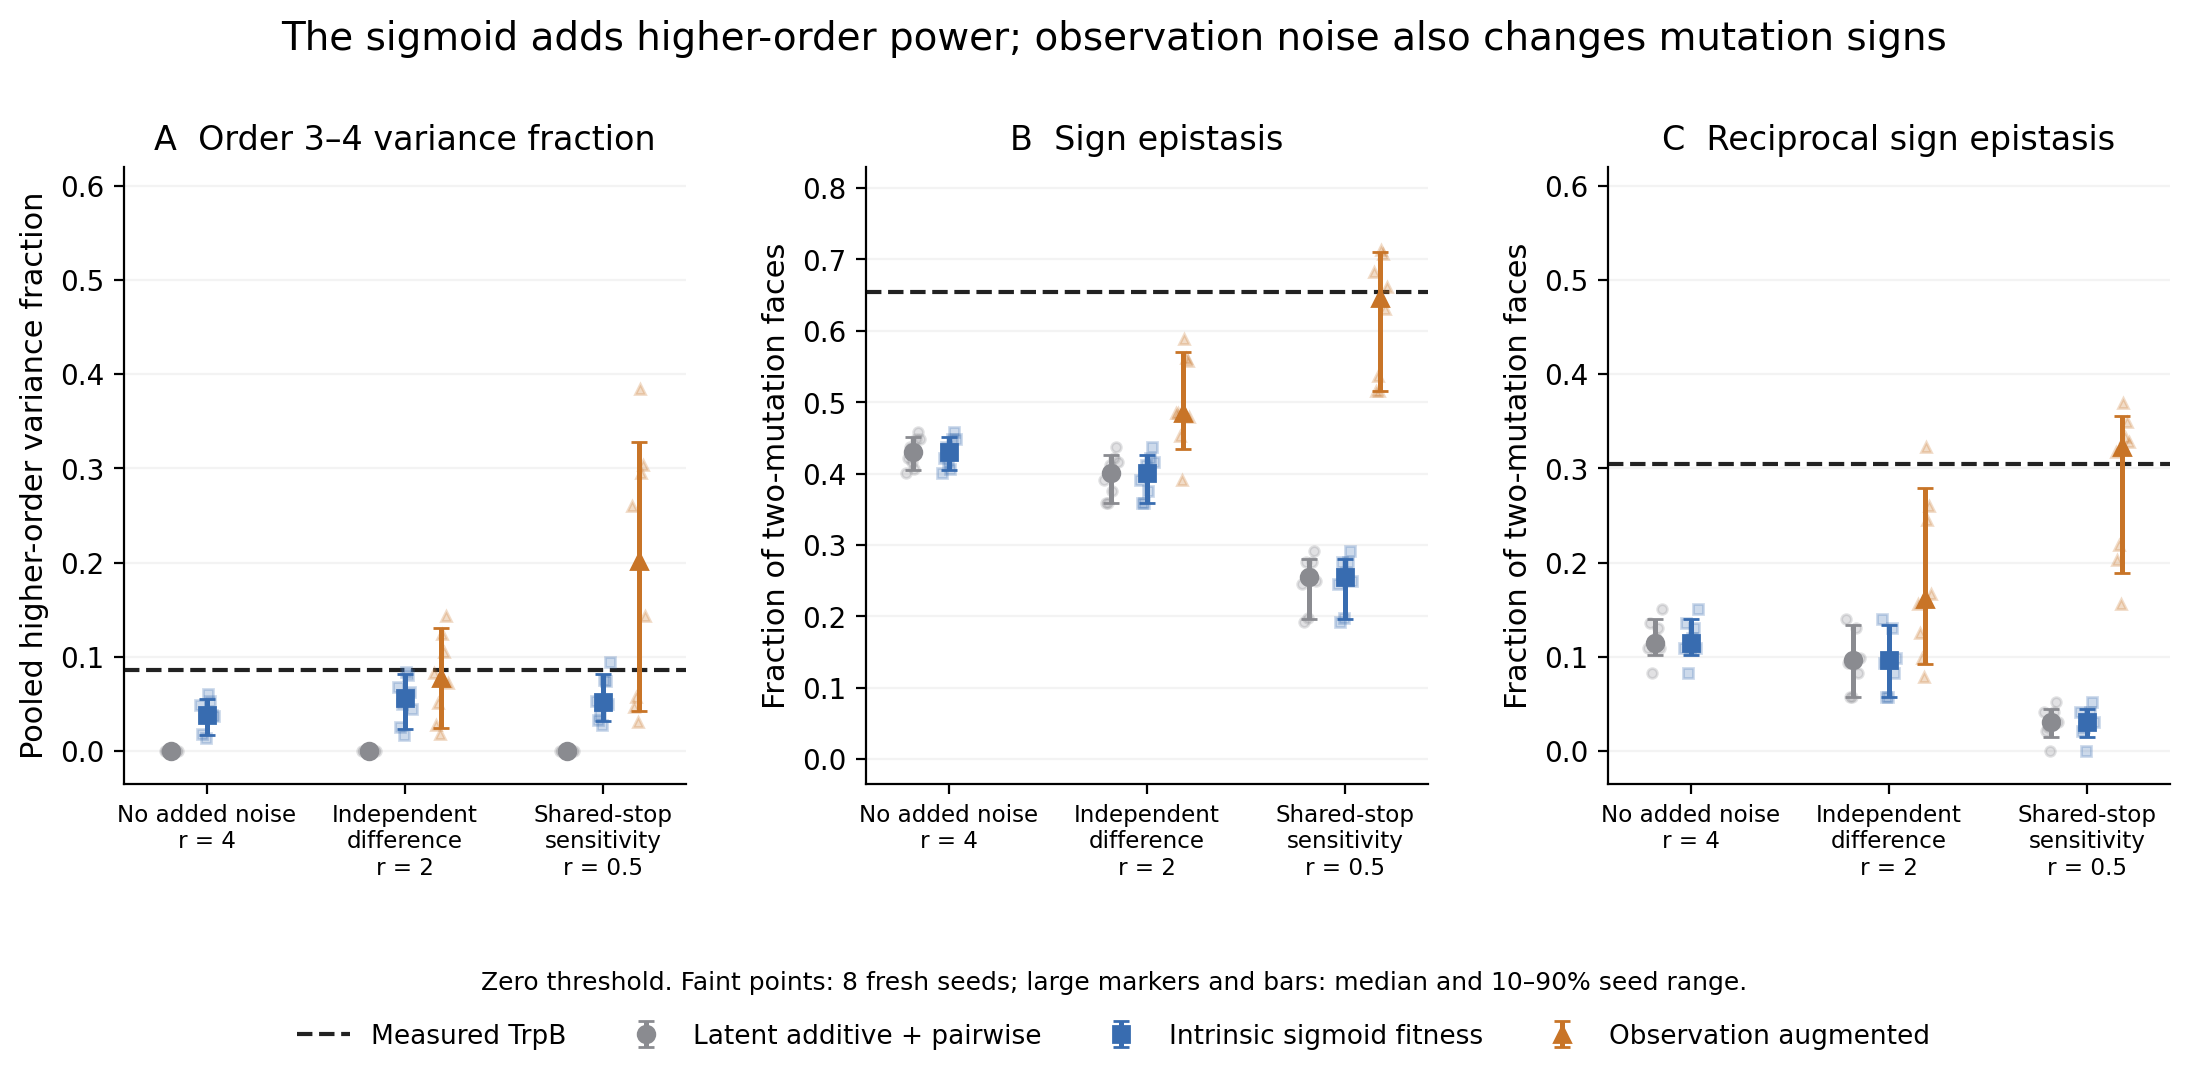

In [3]:
display(Image(filename=str(architecture.stage_figure(frame, ANA))))

## Numerical comparison on the primary resolution

The table below uses the historical positive resolution, so its sign-epistasis
entries differ from the zero-threshold illustration above. No seed is excluded.
The full tables also retain latent metrics, all interaction orders, all three
resolutions, individual cube powers, and both seed cohorts.

In [4]:
metrics = ['epistatic_fraction', 'ho_fraction', 'pooled_epistatic_fraction', 'pooled_ho_fraction',
           'sign_epistasis_fraction', 'reciprocal_sign_epistasis_fraction']
primary = frame.loc[frame.relative_resolution.eq(.001)]
reference = primary.loc[primary.cohort.eq('empirical'), metrics].copy()
reference.index = ['Measured TrpB · 32 cubes']
display(reference.round(4))
for cohort in ['fresh', 'reused']:
    print(f'{cohort.capitalize()} seed medians')
    display(primary.loc[primary.cohort.eq(cohort)].groupby(['observation', 'layer'])[metrics].median().round(4))
print('Tables saved in', ANA / 'tables')

,epistatic_fraction,ho_fraction,pooled_epistatic_fraction,pooled_ho_fraction,sign_epistasis_fraction,reciprocal_sign_epistasis_fraction
Measured TrpB · 32 cubes,0.6876,0.3156,0.3297,0.0862,0.651,0.2956


Fresh seed medians


epistatic_fraction  ho_fraction  \
observation             layer                                        
independent_difference  intrinsic              0.3847       0.0495   
                        observed               0.4371       0.1102   
none                    intrinsic              0.4287       0.0325   
shared_stop_sensitivity intrinsic              0.3075       0.0399   
                        observed               0.6509       0.2739   

                                   pooled_epistatic_fraction  \
observation             layer                                  
independent_difference  intrinsic                     0.3600   
                        observed                      0.4026   
none                    intrinsic                     0.4014   
shared_stop_sensitivity intrinsic                     0.3563   
                        observed                      0.5605   

                                   pooled_ho_fraction  \
observation             layer                           
independent_difference  intrinsic              0.0565   
                        observed               0.0771   
none                    intrinsic              0.0379   
shared_stop_sensitivity intrinsic              0.0518   
                        observed               0.2018   

                                   sign_epistasis_fraction  \
observation             layer                                
independent_difference  intrinsic                   0.3620   
                        observed                    0.4766   
none                    intrinsic                   0.4219   
shared_stop_sensitivity intrinsic                   0.0990   
                        observed                    0.6406   

                                   reciprocal_sign_epistasis_fraction  
observation             layer                                          
independent_difference  intrinsic                              0.0859  
                        observed                               0.1536  
none                    intrinsic                              0.1146  
shared_stop_sensitivity intrinsic                              0.0104  
                        observed                               0.3151

Reused seed medians


epistatic_fraction  ho_fraction  \
observation             layer                                        
independent_difference  intrinsic              0.4097       0.0477   
                        observed               0.5713       0.1956   
none                    intrinsic              0.4348       0.0319   
shared_stop_sensitivity intrinsic              0.3090       0.0512   
                        observed               0.6893       0.2878   

                                   pooled_epistatic_fraction  \
observation             layer                                  
independent_difference  intrinsic                     0.3708   
                        observed                      0.4724   
none                    intrinsic                     0.3799   
shared_stop_sensitivity intrinsic                     0.3950   
                        observed                      0.6419   

                                   pooled_ho_fraction  \
observation             layer                           
independent_difference  intrinsic              0.0522   
                        observed               0.1226   
none                    intrinsic              0.0381   
shared_stop_sensitivity intrinsic              0.0779   
                        observed               0.2732   

                                   sign_epistasis_fraction  \
observation             layer                                
independent_difference  intrinsic                   0.3646   
                        observed                    0.5833   
none                    intrinsic                   0.4167   
shared_stop_sensitivity intrinsic                   0.0443   
                        observed                    0.6276   

                                   reciprocal_sign_epistasis_fraction  
observation             layer                                          
independent_difference  intrinsic                              0.0833  
                        observed                               0.2422  
none                    intrinsic                              0.1094  
shared_stop_sensitivity intrinsic                              0.0052  
                        observed                               0.2839

Tables saved in /Users/matthewspence/Documents/Documents/project-adapt-env/analyses/2026-11-25_ANA-072_run-186-trpb-landscape-behaviour-architecture-and-difficulty-proxies/tables


## What architecture information is and is not recovered

The model makes its generative assumptions inspectable: biological marginal
amino-acid preferences, an additive/pairwise mutation-RMS ratio $r$, a Gaussian
interaction ensemble, and a nonlinear readout. $r$ is not an observable epistatic
variance fraction. This calibration does not infer the identity, sign or strength
of particular TrpB residue-pair couplings, nor physical free energies. The
profile itself is evolutionary marginal information, not fitted assay fitness.
The seed-selected reference is a computational centering anchor, not a biological
wild type.

No Thornton/Park auxiliary inference was fitted in RUN-186. The published
additive-plus-specific-epistasis-plus-nonlinear-readout architecture motivates
the functional family; the synthetic coefficient distribution and sparse
generation choices remain model assumptions. The four-site system includes all
six site pairs, while larger systems can have a restricted support graph.
The coefficients here are generated, not recovered from TrpB observations.

The current comparison supports conditional aggregate architecture resemblance
and exposes a material pooled-power mismatch. It does not establish transfer to
other proteins, larger sequence spaces, or learning performance. In particular,
observed high-order signal may be due to the global readout or observation error;
it is not evidence for biological three- or four-body latent interactions.